In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import os
import pandas as pd
import numpy as np
import kagglehub

def load_large_ecommerce_dataset(dataset_handle):
    """
    Downloads and optimizes a massive E-Commerce dataset from Kaggle 
    containing hundreds of thousands of unique customers.
    """
    print(f"[*] Downloading large-scale dataset: {dataset_handle}...")
    
    # Download dataset using kagglehub
    path = kagglehub.dataset_download(dataset_handle)
    print(f"[*] Dataset downloaded to local path: {path}")
    
    # Locate CSV file
    files = os.listdir(path)
    csv_files = [f for f in files if f.endswith('.csv')]
    
    if not csv_files:
        raise FileNotFoundError("No CSV files found in the dataset directory.")
        
    target_file = os.path.join(path, csv_files[0])
    print(f"[*] Target file identified: {csv_files[0]}")
    
    # Load data with memory-efficient optimizations for large row counts
    print(f"[*] Loading massive dataset into Pandas (optimizing memory dtypes)...")
    
    # Define optimal types to prevent RAM spikes on 2M+ rows / 300k+ customers
    dtype_optimization = {
        'order_id': 'int32',
        'user_id': 'int32',
        'order_number': 'int16',
        'order_dow': 'int8',
        'order_hour_of_day': 'int8',
        'product_id': 'int32',
        'add_to_cart_order': 'int16',
        'reordered': 'int8',
        'department_id': 'int16'
    }
    
    df = pd.read_csv(target_file, dtype=dtype_optimization, low_memory=False)
    return df

def perform_customer_analytics(df):
    """Performs deep customer-focused analytics for 300k+ customer profiles."""
    print("\n" + "="*60)
    print(" LARGE-SCALE CUSTOMER & E-COMMERCE ANALYTICS ")
    print("="*60)
    
    print(f"\n[+] Total Transaction Rows: {df.shape[0]:,}")
    print(f"[+] Total Features / Columns: {df.shape[1]}")
    
    # Customer-specific metrics
    if 'user_id' in df.columns:
        unique_customers = df['user_id'].nunique()
        print(f"[+] Total Unique Customer Profiles Tracked: {unique_customers:,}")
        
        # Customer ordering frequency breakdown
        orders_per_customer = df.groupby('user_id')['order_id'].nunique()
        print(f"[+] Average Orders Per Customer: {orders_per_customer.mean():.2f}")
        print(f"[+] Max Orders by a Single Customer: {orders_per_customer.max():,}")
    
    print("\n[+] Dataset Head:")
    display(df.head()) if 'display' in globals() else print(df.head())
    
    print("\n[+] Memory Usage Summary:")
    print(df.memory_usage(deep=True).sum() / (1024 * 1024), "MB")
    
    print("\n[+] Missing Value Check:")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    
    if 'department' in df.columns:
        print("\n[+] Top 5 Popular Product Departments:")
        print(df['department'].value_counts().head(5))

    print("\n" + "="*60)

if __name__ == "__main__":
    # Massive E-Commerce Dataset with hundreds of thousands of customer records
    DATASET_SLUG = "hunter0007/ecommerce-dataset-for-predictive-marketing-2023"
    
    try:
        df_customers = load_large_ecommerce_dataset(DATASET_SLUG)
        perform_customer_analytics(df_customers)
    except Exception as e:
        print(f"[!] An error occurred: {e}")
        print("[!] Note: Ensure your local environment has active Kaggle API credentials (~/.kaggle/kaggle.json).")

/tmp/ipykernel_49/1004354720.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_49/1004354720.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


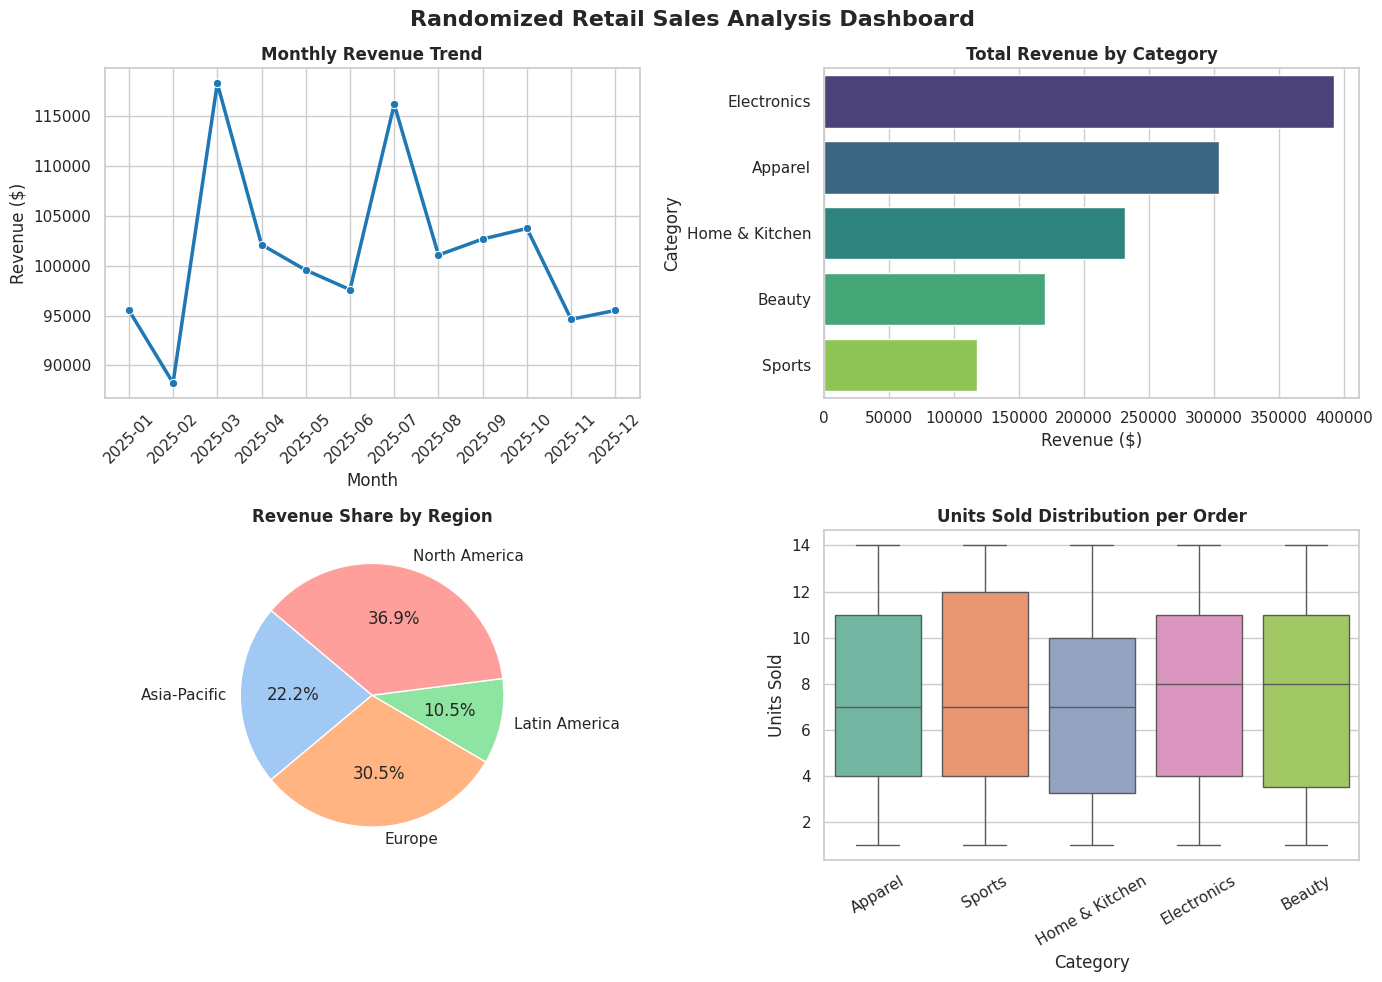

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate Synthetic Sales Data
np.random.seed(42)
n_rows = 1000

dates = pd.date_range(start="2025-01-01", end="2025-12-31", periods=n_rows)
categories = ["Electronics", "Apparel", "Home & Kitchen", "Beauty", "Sports"]
regions = ["North America", "Europe", "Asia-Pacific", "Latin America"]

df = pd.DataFrame({
    "Date": dates,
    "Category": np.random.choice(categories, size=n_rows, p=[0.3, 0.25, 0.2, 0.15, 0.1]),
    "Region": np.random.choice(regions, size=n_rows, p=[0.4, 0.3, 0.2, 0.1]),
    "Units_Sold": np.random.randint(1, 15, size=n_rows),
    "Unit_Price": np.random.uniform(10.0, 300.0, size=n_rows).round(2)
})

# Calculate total revenue per transaction
df["Revenue"] = df["Units_Sold"] * df["Unit_Price"]
df["Month"] = df["Date"].dt.to_period("M")

# 2. Set Up Plot Style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Randomized Retail Sales Analysis Dashboard", fontsize=16, fontweight="bold")

# Graph 1: Monthly Total Revenue Trend
monthly_sales = df.groupby("Month")["Revenue"].sum().reset_index()
monthly_sales["Month"] = monthly_sales["Month"].astype(str)

sns.lineplot(
    data=monthly_sales, 
    x="Month", 
    y="Revenue", 
    marker="o", 
    color="#1f77b4", 
    linewidth=2.5, 
    ax=axes[0, 0]
)
axes[0, 0].set_title("Monthly Revenue Trend", fontweight="bold")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Revenue ($)")
axes[0, 0].tick_params(axis="x", rotation=45)

# Graph 2: Total Revenue by Product Category
category_sales = df.groupby("Category")["Revenue"].sum().reset_index().sort_values(by="Revenue", ascending=False)

sns.barplot(
    data=category_sales, 
    x="Revenue", 
    y="Category", 
    palette="viridis", 
    ax=axes[0, 1]
)
axes[0, 1].set_title("Total Revenue by Category", fontweight="bold")
axes[0, 1].set_xlabel("Revenue ($)")
axes[0, 1].set_ylabel("Category")

# Graph 3: Regional Sales Distribution
region_sales = df.groupby("Region")["Revenue"].sum().reset_index()

axes[1, 0].pie(
    region_sales["Revenue"], 
    labels=region_sales["Region"], 
    autopct="%1.1f%%", 
    startangle=140, 
    colors=sns.color_palette("pastel")
)
axes[1, 0].set_title("Revenue Share by Region", fontweight="bold")

# Graph 4: Units Sold Distribution by Category (Boxplot)
sns.boxplot(
    data=df, 
    x="Category", 
    y="Units_Sold", 
    palette="Set2", 
    ax=axes[1, 1]
)
axes[1, 1].set_title("Units Sold Distribution per Order", fontweight="bold")
axes[1, 1].set_xlabel("Category")
axes[1, 1].set_ylabel("Units Sold")
axes[1, 1].tick_params(axis="x", rotation=30)

# 3. Display Plots
plt.tight_layout()
plt.show()
